In [1]:
from abc import ABC
import torchvision
import torchvision.transforms as transforms
import numpy as np
import time
import matplotlib.pyplot as plt

In [ ]:
class Linear:
    def __init__(self, size_in, size_out):
        self.weight = np.random.uniform(-1, 1, (size_in, size_out)) / np.sqrt(size_in)
        self.bias = np.zeros(size_out)

    def __call__(self, input):
        self.input = input
        return input @ self.weight + self.bias

    def backward(self, grad_out):
        self.grad_weight = self.input.T @ grad_out
        self.grad_bias = grad_out.sum(0)
        return grad_out @ self.weight.T

class ReLU:
    def __call__(self, input):
        self.input = input
        return np.maximum(0, input)

    def backward(self, grad_output):
        grad_input = (self.input > 0).astype(int)
        return grad_input * grad_output

class CrossEntropyLoss:
    def softmax(self, input):
        temp = np.exp(input - input.max(1, keepdims=True))
        return temp / temp.sum(1, keepdims=True)

    def __call__(self, input, target):
        temp = self.softmax(input)[np.arange(input.shape[0]), target]

        out = -1 / target.shape[0] * np.sum(np.log(temp))
        return out
    def backward(self, input, target):
        temp = self.softmax(input)
        temp[np.arange(len(target)), target] -= 1
        return temp / len(target)

class Model:
    def __init__(self, n_hidden):
        self.linear1 = Linear(28*28, n_hidden)
        self.linear2 = Linear(n_hidden, 10)
        self.relu = ReLU()
    def __call__(self,X):
        return self.forward(X)
    def forward(self, X):
        temp = self.linear1(X)
        temp = self.relu(temp)
        temp = self.linear2(temp)
        return temp

    def backward(self, grad_out):
        grad_linear2 = self.linear2.backward(grad_out)
        grad_relu = self.relu.backward(grad_linear2)
        self.linear1.backward(grad_relu)

    def step(self, lr=0.1):
        for l in (self.linear1, self.linear2):
            l.weight -= lr * l.grad_weight
            l.bias -= lr * l.grad_bias

In [ ]:
class DataLoader:
    def __init__(self, X, y, batch_size=1, shuffle=False):
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.batch_id = 0
    def __len__(self) -> int:
        return int(np.ceil(self.X.shape[0] / self.batch_size))
    def __iter__(self):
        self.batch_id = 0
        return self
    def __next__(self):
        lower_bound = self.batch_id * self.batch_size
        higher_bound = min(lower_bound + self.batch_size, self.X.shape[0])
        if lower_bound >= self.X.shape[0]:
            raise StopIteration
        batch = (self.X[lower_bound:higher_bound], self.y[lower_bound:higher_bound])
        self.batch_id += 1
        return batch

In [ ]:
train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
)

test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 36.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.11MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.21MB/s]


In [ ]:
print(f"train size: {len(train_dataset)} ")
print(f"test size: {len(test_dataset)}")

train size: 60000 
test size: 10000


In [ ]:
X_train = np.array([x[0] for x in train_dataset])
y_train = np.array([x[1] for x in train_dataset])
X_test = np.array([x[0] for x in test_dataset])
y_test = np.array([x[1] for x in test_dataset])

In [ ]:
print('размер картинки - ', X_train[0].shape)
print('label - ',y_train[0])

размер картинки -  (28, 28)
label -  5


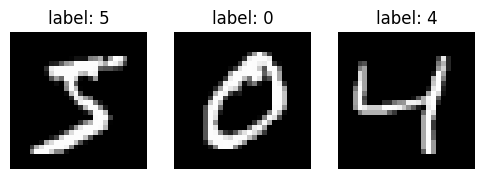

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(6, 2))
for ax, img, label in zip(axes, X_train[:3], y_train[:3]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"label: {label}"); ax.axis("off")
plt.show()

In [ ]:
mean, std = X_train.mean(), X_train.std()
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [ ]:
hidden_size = 300
epochs = 10
batch_size = 128
learning_rate = 0.1


model = Model(hidden_size)
criterion = CrossEntropyLoss()

In [ ]:
train_loader = DataLoader(X_train,y_train,batch_size)
test_loader = DataLoader(X_test,y_test,batch_size)

In [ ]:
for epoch in range(1,epochs+1):
    start_time = time.perf_counter()
    train_loss = 0
    train_accuracy = 0
    for images, labels in train_loader:
        images = images.reshape((images.shape[0],-1))
        logits = model(images)
        model.backward(criterion.backward(logits, labels))
        model.step(learning_rate)
        train_loss += criterion(logits, labels) * images.shape[0]
        train_accuracy += (logits.argmax(axis = -1) == labels).sum()
    train_loss = train_loss/len(train_loader.X)
    train_accuracy = train_accuracy/len(train_loader.X)
    end_time = time.perf_counter()
    execution_time = end_time - start_time
    print(f'{epoch} epoch  loss - {train_loss:0.3f}   time - {execution_time:0.3f} sec  train_accuracy - {train_accuracy:0.3f}')

1 epoch  loss - 0.322   time - 4.194 sec  train_accuracy - 0.909
2 epoch  loss - 0.149   time - 4.194 sec  train_accuracy - 0.957
3 epoch  loss - 0.105   time - 6.871 sec  train_accuracy - 0.970
4 epoch  loss - 0.081   time - 4.245 sec  train_accuracy - 0.978
5 epoch  loss - 0.065   time - 5.937 sec  train_accuracy - 0.982
6 epoch  loss - 0.054   time - 5.112 sec  train_accuracy - 0.985
7 epoch  loss - 0.045   time - 4.053 sec  train_accuracy - 0.988
8 epoch  loss - 0.038   time - 6.710 sec  train_accuracy - 0.990
9 epoch  loss - 0.033   time - 4.125 sec  train_accuracy - 0.992
10 epoch  loss - 0.028   time - 4.177 sec  train_accuracy - 0.994


In [ ]:
test_accuracy = 0
for images, labels in test_loader:
    images = images.reshape((images.shape[0],-1))
    logits = model(images)
    test_accuracy += (logits.argmax(axis = -1) == labels).sum()
test_accuracy = test_accuracy/len(test_loader.X)
print(f'test_accuracy - {test_accuracy}')


test_accuracy - 0.9797
